In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score

np.random.seed(42)

print("Libraries loaded successfully")

Libraries loaded successfully


In [64]:
TRAIN_PATH = "../data/processed/train.csv"
VALIDATION_PATH = "../data/processed/validation.csv"
TEST_PATH = "../data/processed/test.csv"

train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Testing:", test_df.shape)

train_df.head()

Training: (4842, 14)
Validation: (1012, 14)
Testing: (1012, 14)


,project_id,project_type,task_description,category,required_skills,skill_count,complexity,priority,estimated_hours,actual_hours,deadline_days,team_size,dependency,delay_hours
0,2,Food Delivery,design database schema for user profiles,database,mysql,1,5,high,11,16,6,6,none,5
1,2,Food Delivery,create a responsive website,frontend,react,1,3,high,15,13,8,6,none,0
2,2,Food Delivery,manage cloud services on heroku,cloud,google cloud,1,5,medium,21,26,13,6,none,5
3,2,Food Delivery,test frontend components,testing,jest,1,4,high,14,20,7,6,create a responsive website,6
4,2,Food Delivery,build interactive forms,frontend,typescript,1,1,low,5,4,1,6,none,0


In [65]:
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum())

['project_id', 'project_type', 'task_description', 'category', 'required_skills', 'skill_count', 'complexity', 'priority', 'estimated_hours', 'actual_hours', 'deadline_days', 'team_size', 'dependency', 'delay_hours']

Missing values:
project_id          0
project_type        0
task_description    0
category            0
required_skills     0
skill_count         0
complexity          0
priority            0
estimated_hours     0
actual_hours        0
deadline_days       0
team_size           0
dependency          0
delay_hours         0
dtype: int64


In [66]:
def create_input_text(df):

    return (
        df["project_type"].astype(str)
        + " "
        + df["task_description"].astype(str)
    )


train_text = create_input_text(train_df)

validation_text = create_input_text(validation_df)

test_text = create_input_text(test_df)

print(train_text.head())

0    Food Delivery design database schema for user ...
1            Food Delivery create a responsive website
2        Food Delivery manage cloud services on heroku
3               Food Delivery test frontend components
4                Food Delivery build interactive forms
dtype: object


In [67]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train = tfidf.fit_transform(train_text)

X_validation = tfidf.transform(validation_text)

X_test = tfidf.transform(test_text)

print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_validation.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (4842, 1175)
Validation feature shape: (1012, 1175)
Testing feature shape: (1012, 1175)


CELL 6 TRAIN CATEGORY MODEL


In [68]:
y_category_train = train_df["category"]
y_category_validation = validation_df["category"]
y_category_test = test_df["category"]

category_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

category_model.fit(
    X_train,
    y_category_train
)

print("Category model trained")

Category model trained


In [69]:
category_predictions = category_model.predict(
    X_test
)

category_accuracy = accuracy_score(
    y_category_test,
    category_predictions
)

print(
    "Category Test Accuracy:",
    round(category_accuracy, 4)
)

print()

print(
    classification_report(
        y_category_test,
        category_predictions,
        zero_division=0
    )
)

Category Test Accuracy: 0.998

              precision    recall  f1-score   support

       ai/ml       0.99      1.00      0.99       138
     backend       1.00      1.00      1.00       204
       cloud       1.00      1.00      1.00        99
data science       1.00      0.83      0.91        12
    database       1.00      1.00      1.00        57
      devops       1.00      1.00      1.00        69
    frontend       1.00      1.00      1.00       186
     testing       1.00      1.00      1.00       203
ui/ux design       1.00      1.00      1.00        44

    accuracy                           1.00      1012
   macro avg       1.00      0.98      0.99      1012
weighted avg       1.00      1.00      1.00      1012



VALIDATE CATEGORY MODEL

In [70]:
category_validation_predictions = (
    category_model.predict(X_validation)
)

category_validation_accuracy = accuracy_score(
    y_category_validation,
    category_validation_predictions
)

print(
    "Validation Accuracy:",
    round(category_validation_accuracy, 4)
)

Validation Accuracy: 1.0


CELL 8 :FINAL CATEGORY TEST

In [71]:
category_validation_predictions = (
    category_model.predict(X_validation)
)

category_validation_accuracy = accuracy_score(
    y_category_validation,
    category_validation_predictions
)

print(
    "Validation Accuracy:",
    round(category_validation_accuracy, 4)
)

Validation Accuracy: 1.0


COMPLEXITY PREDICTION

In [72]:
y_complexity_train = train_df["complexity"]
y_complexity_validation = validation_df["complexity"]
y_complexity_test = test_df["complexity"]

complexity_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

complexity_model.fit(
    X_train,
    y_complexity_train
)

complexity_predictions = complexity_model.predict(
    X_test
)

complexity_accuracy = accuracy_score(
    y_complexity_test,
    complexity_predictions
)

print(
    "Complexity Accuracy:",
    round(complexity_accuracy, 4)
)

Complexity Accuracy: 0.1966


In [73]:
print(
    classification_report(
        y_complexity_test,
        complexity_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           1       0.20      0.23      0.21       200
           2       0.17      0.15      0.16       209
           3       0.21      0.23      0.22       195
           4       0.16      0.14      0.15       195
           5       0.24      0.23      0.23       213

    accuracy                           0.20      1012
   macro avg       0.20      0.20      0.20      1012
weighted avg       0.20      0.20      0.20      1012



MODEL 3 — PRIORITY PREDICTION

In [74]:
y_priority_train = train_df["priority"]
y_priority_validation = validation_df["priority"]
y_priority_test = test_df["priority"]

priority_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

priority_model.fit(
    X_train,
    y_priority_train
)

priority_predictions = priority_model.predict(
    X_test
)

priority_accuracy = accuracy_score(
    y_priority_test,
    priority_predictions
)

print(
    "Priority Accuracy:",
    round(priority_accuracy, 4)
)

print()

print(
    classification_report(
        y_priority_test,
        priority_predictions,
        zero_division=0
    )
)

Priority Accuracy: 0.3706

              precision    recall  f1-score   support

        high       0.36      0.37      0.37       373
         low       0.18      0.10      0.13       205
      medium       0.42      0.50      0.46       434

    accuracy                           0.37      1012
   macro avg       0.32      0.32      0.32      1012
weighted avg       0.35      0.37      0.36      1012



MODEL 4 — ESTIMATED HOURS

In [75]:
y_hours_train = train_df["estimated_hours"]
y_hours_validation = validation_df["estimated_hours"]
y_hours_test = test_df["estimated_hours"]

hours_model = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    n_jobs=-1
)

hours_model.fit(
    X_train,
    y_hours_train
)

hours_predictions = hours_model.predict(
    X_test
)

mae = mean_absolute_error(
    y_hours_test,
    hours_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_hours_test,
        hours_predictions
    )
)

r2 = r2_score(
    y_hours_test,
    hours_predictions
)

print("Estimated Hours Model")

print(
    "MAE:",
    round(mae, 3)
)

print(
    "RMSE:",
    round(rmse, 3)
)

print(
    "R2:",
    round(r2, 3)
)

Estimated Hours Model
MAE: 5.166
RMSE: 6.348
R2: -0.183


CELL 13 — Predicted vs actual estimated hours

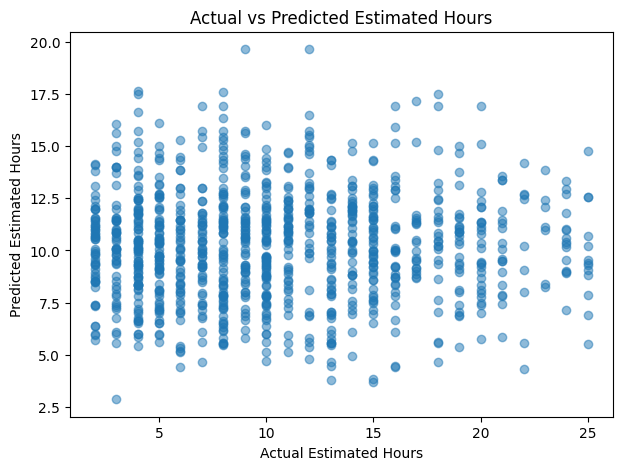

In [76]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_hours_test,
    hours_predictions,
    alpha=0.5
)

plt.xlabel("Actual Estimated Hours")
plt.ylabel("Predicted Estimated Hours")

plt.title(
    "Actual vs Predicted Estimated Hours"
)

plt.show()

MODEL 5 — REQUIRED SKILLS ⭐

In [77]:
def split_skills(value):

    return [
        skill.strip()
        for skill in str(value).split(",")
        if skill.strip()
    ]


train_skills = train_df[
    "required_skills"
].apply(split_skills)

validation_skills = validation_df[
    "required_skills"
].apply(split_skills)

test_skills = test_df[
    "required_skills"
].apply(split_skills)


skill_encoder = MultiLabelBinarizer()

y_skills_train = skill_encoder.fit_transform(
    train_skills
)

y_skills_validation = skill_encoder.transform(
    validation_skills
)

y_skills_test = skill_encoder.transform(
    test_skills
)

print(
    "Number of skills:",
    len(skill_encoder.classes_)
)

print(
    skill_encoder.classes_[:30]
)

Number of skills: 183
['adobe xd' 'adtk' 'alibi detect' 'als' 'angular' 'ansible' 'apache flink'
 'apache spark' 'api' 'aria' 'arima' 'asp.net' 'augmentor' 'aws' 'azure'
 'bash' 'bert' 'biobert' 'bm25' 'bootstrap' 'borutapy' 'c' 'c++' 'carla'
 'catboost' 'chai' 'ci/cd' 'cleverhans' 'cnn' 'collaborative filtering']


TRAIN SKILL MODEL

In [78]:
skill_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    n_jobs=-1
)

skill_model.fit(
    X_train,
    y_skills_train
)

print("Skill model trained")

Skill model trained


EVALUATE SKILLS


In [79]:
skill_predictions = skill_model.predict(
    X_test
)

skill_micro_f1 = f1_score(
    y_skills_test,
    skill_predictions,
    average="micro",
    zero_division=0
)

skill_macro_f1 = f1_score(
    y_skills_test,
    skill_predictions,
    average="macro",
    zero_division=0
)

print(
    "Skill Micro F1:",
    round(skill_micro_f1, 4)
)

print(
    "Skill Macro F1:",
    round(skill_macro_f1, 4)
)

Skill Micro F1: 0.5178
Skill Macro F1: 0.6831


TESTING 1 SKILL PREDICTION-

In [80]:
sample_number = 7

print(
    "Task:",
    test_df.iloc[sample_number][
        "task_description"
    ]
)

print(
    "\nActual skills:",
    test_df.iloc[sample_number][
        "required_skills"
    ]
)

predicted_skill_array = (
    skill_predictions[sample_number]
)

predicted_skills = skill_encoder.classes_[
    predicted_skill_array.astype(bool)
]

print(
    "\nPredicted skills:",
    predicted_skills.tolist()
)

Task: develop rest api for user management

Actual skills: spring boot

Predicted skills: ['spring boot']


MODEL 6 : SEEING DELAY RISK

In [81]:
train_delay = (
    train_df["delay_hours"] > 0
).astype(int)

validation_delay = (
    validation_df["delay_hours"] > 0
).astype(int)

test_delay = (
    test_df["delay_hours"] > 0
).astype(int)

print(
    train_delay.value_counts()
)

delay_hours
1    2985
0    1857
Name: count, dtype: int64


BUILSING DELAY FEATURES

In [82]:
from scipy.sparse import hstack

delay_train_numbers = train_df[
    [
        "complexity",
        "estimated_hours",
        "deadline_days",
        "team_size",
        "skill_count"
    ]
].values

delay_validation_numbers = validation_df[
    [
        "complexity",
        "estimated_hours",
        "deadline_days",
        "team_size",
        "skill_count"
    ]
].values

delay_test_numbers = test_df[
    [
        "complexity",
        "estimated_hours",
        "deadline_days",
        "team_size",
        "skill_count"
    ]
].values


X_delay_train = hstack(
    [
        X_train,
        delay_train_numbers
    ]
)

X_delay_validation = hstack(
    [
        X_validation,
        delay_validation_numbers
    ]
)

X_delay_test = hstack(
    [
        X_test,
        delay_test_numbers
    ]
)

TRAIN DELAY MODEL: 

In [83]:
delay_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

delay_model.fit(
    X_delay_train,
    train_delay
)

delay_predictions = delay_model.predict(
    X_delay_test
)

delay_accuracy = accuracy_score(
    test_delay,
    delay_predictions
)

delay_f1 = f1_score(
    test_delay,
    delay_predictions,
    zero_division=0
)

print(
    "Delay Accuracy:",
    round(delay_accuracy, 4)
)

print(
    "Delay F1:",
    round(delay_f1, 4)
)

print()

print(
    classification_report(
        test_delay,
        delay_predictions,
        zero_division=0
    )
)

Delay Accuracy: 0.582
Delay F1: 0.6331

              precision    recall  f1-score   support

           0       0.46      0.58      0.51       387
           1       0.69      0.58      0.63       625

    accuracy                           0.58      1012
   macro avg       0.58      0.58      0.57      1012
weighted avg       0.60      0.58      0.59      1012



In [84]:
results = pd.DataFrame({

    "Model": [
        "Category",
        "Complexity",
        "Priority",
        "Required Skills",
        "Delay Risk"
    ],

    "Metric": [
        "Accuracy",
        "Accuracy",
        "Accuracy",
        "Micro F1",
        "F1"
    ],

    "Score": [
        category_accuracy,
        complexity_accuracy,
        priority_accuracy,
        skill_micro_f1,
        delay_f1
    ]
})

results

,Model,Metric,Score
0,Category,Accuracy,0.998024
1,Complexity,Accuracy,0.196640
2,Priority,Accuracy,0.370553
3,Required Skills,Micro F1,0.517766
4,Delay Risk,F1,0.633131


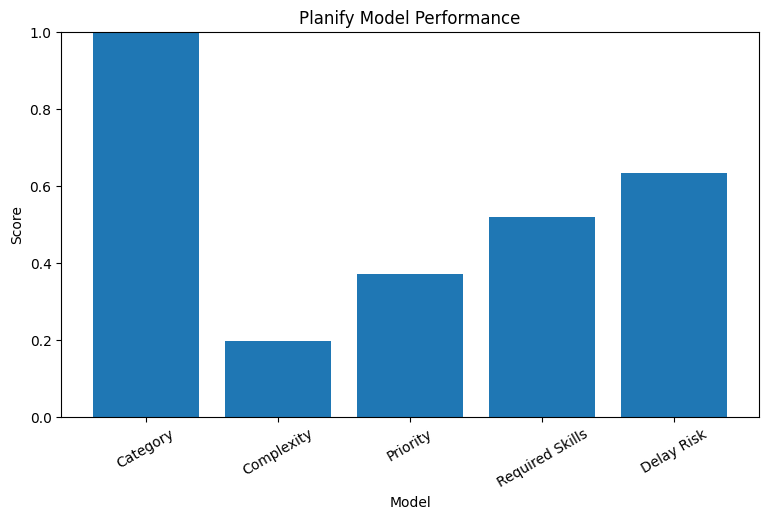

In [85]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Score"]
)

plt.ylim(0, 1)

plt.xlabel("Model")
plt.ylabel("Score")

plt.title(
    "Planify Model Performance"
)

plt.xticks(rotation=30)

plt.show()

SAVING

In [86]:
MODEL_DIR = "models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print(
    "Model directory created:",
    MODEL_DIR
)


joblib.dump(
    tfidf,
    os.path.join(
        MODEL_DIR,
        "tfidf_vectorizer.pkl"
    )
)

joblib.dump(
    category_model,
    os.path.join(
        MODEL_DIR,
        "category_model.pkl"
    )
)

joblib.dump(
    complexity_model,
    os.path.join(
        MODEL_DIR,
        "complexity_model.pkl"
    )
)

joblib.dump(
    priority_model,
    os.path.join(
        MODEL_DIR,
        "priority_model.pkl"
    )
)

joblib.dump(
    hours_model,
    os.path.join(
        MODEL_DIR,
        "hours_model.pkl"
    )
)

joblib.dump(
    skill_model,
    os.path.join(
        MODEL_DIR,
        "skill_model.pkl"
    )
)

joblib.dump(
    skill_encoder,
    os.path.join(
        MODEL_DIR,
        "skill_encoder.pkl"
    )
)

joblib.dump(
    delay_model,
    os.path.join(
        MODEL_DIR,
        "delay_model.pkl"
    )
)

print("All models saved successfully")

Model directory created: models
All models saved successfully


In [87]:
def predict_task(
    project_type,
    task_description
):

    input_text = (
        project_type
        + " "
        + task_description
    )

    input_vector = tfidf.transform(
        [input_text]
    )

    category = category_model.predict(
        input_vector
    )[0]

    complexity = complexity_model.predict(
        input_vector
    )[0]

    priority = priority_model.predict(
        input_vector
    )[0]

    estimated_hours = hours_model.predict(
        input_vector
    )[0]

    skill_binary = skill_model.predict(
        input_vector
    )

    skills = skill_encoder.inverse_transform(
        skill_binary
    )[0]

    return {
        "category":
            category,

        "skills":
            list(skills),

        "complexity":
            int(complexity),

        "priority":
            priority,

        "estimated_hours":
            round(float(estimated_hours), 1)
    }

In [88]:
result = predict_task(
    "E-Commerce",
    "implement secure user authentication api"
)

result

{'category': 'backend',
 'skills': ['api',
  'asp.net',
  'c',
  'c++',
  'database',
  'django',
  'flask',
  'go',
  'java',
  'kotlin',
  'laravel',
  'node.js',
  'php',
  'python',
  'ruby',
  'rust',
  'scala',
  'spring boot'],
 'complexity': 2,
 'priority': 'medium',
 'estimated_hours': 7.6}

In [89]:
test_examples = [
    (
        "E-Commerce",
        "create responsive checkout interface"
    ),

    (
        "Healthcare",
        "train image classification model for medical images"
    ),

    (
        "Banking",
        "implement secure transaction api"
    ),

    (
        "Portfolio Website",
        "design responsive mobile navigation"
    ),

    (
        "Food Delivery",
        "create database for restaurant orders"
    )
]


for project, task in test_examples:

    print("=" * 60)

    print("PROJECT:", project)
    print("TASK:", task)

    print(
        predict_task(
            project,
            task
        )
    )

PROJECT: E-Commerce
TASK: create responsive checkout interface
{'category': 'frontend', 'skills': ['bootstrap', 'css', 'foundation', 'javascript', 'jquery', 'react', 'redux', 'sass', 'typescript', 'ui', 'user-friendly', 'ux', 'vue'], 'complexity': 3, 'priority': 'medium', 'estimated_hours': 9.6}
PROJECT: Healthcare
TASK: train image classification model for medical images
{'category': 'ai/ml', 'skills': [], 'complexity': 3, 'priority': 'medium', 'estimated_hours': 11.0}
PROJECT: Banking
TASK: implement secure transaction api
{'category': 'backend', 'skills': [], 'complexity': 2, 'priority': 'medium', 'estimated_hours': 9.5}
PROJECT: Portfolio Website
TASK: design responsive mobile navigation
{'category': 'frontend', 'skills': ['angular', 'javascript', 'jquery', 'sass'], 'complexity': 2, 'priority': 'medium', 'estimated_hours': 9.8}
PROJECT: Food Delivery
TASK: create database for restaurant orders
{'category': 'backend', 'skills': [], 'complexity': 3, 'priority': 'high', 'estimated_hou

In [90]:
print("=" * 60)
print("PLANIFY PHASE 3 - BASELINE TRAINING COMPLETE")
print("=" * 60)

print(
    "Category Accuracy:",
    round(category_accuracy, 4)
)

print(
    "Complexity Accuracy:",
    round(complexity_accuracy, 4)
)

print(
    "Priority Accuracy:",
    round(priority_accuracy, 4)
)

print(
    "Skill Micro F1:",
    round(skill_micro_f1, 4)
)

print(
    "Hours MAE:",
    round(mae, 3)
)

print(
    "Hours RMSE:",
    round(rmse, 3)
)

print(
    "Hours R2:",
    round(r2, 3)
)

print(
    "Delay F1:",
    round(delay_f1, 4)
)

print()
print(
    "Baseline models saved successfully."
)

PLANIFY PHASE 3 - BASELINE TRAINING COMPLETE
Category Accuracy: 0.998
Complexity Accuracy: 0.1966
Priority Accuracy: 0.3706
Skill Micro F1: 0.5178
Hours MAE: 5.166
Hours RMSE: 6.348
Hours R2: -0.183
Delay F1: 0.6331

Baseline models saved successfully.
